# Heart Disease Risk Predictor

This notebook builds the model behind the Heart Disease Risk Predictor web app (`app.py`). You type in four everyday health numbers, and the app tells you whether the model leans towards "heart disease present" or "no heart disease".

Here is what happens in the notebook, in order:

1. Load the UCI Cleveland heart disease data
2. Trim it down to the four numbers the app asks for
3. Train a Support Vector Classifier (SVC)
4. Check how well it does on data it hasn't seen
5. Save the model to `heart_disease_model.pkl`, which is the file the app loads
6. Try a prediction by hand, exactly the way the app does it

> This is a learning project, not a medical tool. Please don't use it to make health decisions.

## What the app needs

The web app has four input boxes, so those are the only features the model is trained on:

| Feature | What it means | Box in the app |
|---|---|---|
| `age` | Age in years | Age (years) |
| `trestbps` | Resting blood pressure (mm Hg) | Resting Blood Pressure |
| `chol` | Serum cholesterol (mg/dl) | Serum Cholesterol |
| `thalach` | Maximum heart rate achieved | Maximum Heart Rate |

The model predicts one thing, `heart_disease`: **0** for no heart disease and **1** for heart disease present.

All four inputs are plain numbers, so there is no categorical encoding anywhere in this project. Whatever the user types goes straight into the model.

### Before you run this

Download the Cleveland processed file from the [UCI Heart Disease page](https://archive.ics.uci.edu/dataset/45/heart+disease), rename it to `processed.cleveland.data`, and put it next to this notebook:

```text
Heart_Disease_ML/
├── Heart_Disease_ML.ipynb
├── processed.cleveland.data
├── app.py
├── requirements.txt
└── README.md
```

## 1. Imports

pandas and numpy handle the data, scikit-learn handles the model and the scoring, `pickle` saves the trained model, and matplotlib with seaborn draws the confusion matrix at the end of the evaluation.

In [1]:
import numpy as np
import pandas as pd
import pickle

from sklearn.model_selection import train_test_split
from sklearn import svm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load the data

The raw UCI file has no header row, so the 14 column names are listed by hand. Missing values are written as `?` in the file, and `na_values="?"` tells pandas to treat them as blanks.

In [2]:
DATA_FILE = "processed.cleveland.data"

UCI_COLUMNS = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"
]

heart_data = pd.read_csv(
    DATA_FILE,
    header=None,
    names=UCI_COLUMNS,
    na_values="?"
)

print("Raw UCI Cleveland data")
print("----------------------")
print(heart_data.head())

print("\nShape:", heart_data.shape)
print("Columns:", heart_data.columns.tolist())

Raw UCI Cleveland data
----------------------
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  num  
0    3.0  0.0   6.0    0  
1    2.0  3.0   3.0    2  
2    2.0  2.0   7.0    1  
3    3.0  0.0   3.0    0  
4    1.0  0.0   3.0    0  

Shape: (303, 14)
Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']


## 3. Look at the data and clean it up

### 3.1 Quick look

A fast check of the column types and how many values are missing, before deciding what to keep.

In [3]:
print("Rows:", len(heart_data))

print("\nData types:")
print(heart_data.dtypes)

print("\nMissing values per column:")
print(heart_data.isnull().sum())

Rows: 303

Data types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
num           int64
dtype: object

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64


### 3.2 Keep what the app uses

The raw file has 14 columns, but the app only collects four of them. This cell does three things:

- Keeps the four input columns plus `num`, the original diagnosis column
- Drops any row where one of those values is missing, so the model never sees blanks
- Turns `num` into a simple yes/no. In the original data `0` means no disease and `1` to `4` mean different severities. The app only has a yes/no answer to show, so everything above 0 becomes `1`.

The cleaned table is also saved as `heart_disease.csv` so you can open it and look at it.

In [4]:
FEATURE_COLUMNS = ["age", "trestbps", "chol", "thalach"]   # same order as the app's input boxes
TARGET_COLUMN = "num"

heart_data = heart_data[FEATURE_COLUMNS + [TARGET_COLUMN]].copy()

# make sure everything is numeric, anything unreadable becomes NaN
for column in FEATURE_COLUMNS + [TARGET_COLUMN]:
    heart_data[column] = pd.to_numeric(heart_data[column], errors="coerce")

heart_data = heart_data.dropna().reset_index(drop=True)

# 0 = no disease, 1-4 = disease present  ->  0 / 1
heart_data["heart_disease"] = (heart_data[TARGET_COLUMN] > 0).astype(int)

heart_data = heart_data[FEATURE_COLUMNS + ["heart_disease"]]

print("Cleaned data")
print("------------")
print(heart_data.head())

print("\nShape:", heart_data.shape)
print("Columns:", heart_data.columns.tolist())

print("\nHow many of each class:")
print(heart_data["heart_disease"].value_counts())

heart_data.to_csv("heart_disease.csv", index=False)
print("\nSaved heart_disease.csv")

Cleaned data
------------
    age  trestbps   chol  thalach  heart_disease
0  63.0     145.0  233.0    150.0              0
1  67.0     160.0  286.0    108.0              1
2  67.0     120.0  229.0    129.0              1
3  37.0     130.0  250.0    187.0              0
4  41.0     130.0  204.0    172.0              0

Shape: (303, 5)
Columns: ['age', 'trestbps', 'chol', 'thalach', 'heart_disease']

How many of each class:
heart_disease
0    164
1    139
Name: count, dtype: int64

Saved heart_disease.csv


## 4. Separate the inputs from the answer

`input_features` is what the app will hand to the model. `output_label` is what the model has to predict.

In [5]:
input_features = heart_data[FEATURE_COLUMNS]
output_label = heart_data["heart_disease"]

print("Input features:")
print(input_features.head())

print("\nOutput label:")
print(output_label.head())

print("\nInput shape:", input_features.shape)
print("Output shape:", output_label.shape)

Input features:
    age  trestbps   chol  thalach
0  63.0     145.0  233.0    150.0
1  67.0     160.0  286.0    108.0
2  67.0     120.0  229.0    129.0
3  37.0     130.0  250.0    187.0
4  41.0     130.0  204.0    172.0

Output label:
0    0
1    1
2    1
3    0
4    0
Name: heart_disease, dtype: int64

Input shape: (303, 4)
Output shape: (303,)


## 5. Train the model

### 5.1 Train/test split

80% of the rows are used to train the model and 20% are held back to test it. The split keeps the rows in their original order (`shuffle=False`). Both halves are saved as CSV files so you can see exactly which rows ended up where.

In [6]:
training_data, testing_data = train_test_split(
    heart_data,
    test_size=0.2,
    random_state=0,
    shuffle=False
)

training_data.to_csv("training-data.csv", index=False)
testing_data.to_csv("testing-data.csv", index=False)

print("Training rows:", training_data.shape)
print("Testing rows: ", testing_data.shape)

Training rows: (242, 5)
Testing rows:  (61, 5)


### 5.2 Split each half into inputs and labels

In [7]:
input_vector_train = training_data[FEATURE_COLUMNS]
output_label_train = training_data["heart_disease"]

print("Training inputs:", input_vector_train.shape)
print("Training labels:", output_label_train.shape)

Training inputs: (242, 4)
Training labels: (242,)


### 5.3 Fit the SVC

A Support Vector Classifier looks for the boundary that best separates "disease" from "no disease" in the four-number space. `gamma="auto"` is a simple default that works fine for a small dataset like this one.

In [8]:
svc_model = svm.SVC(gamma="auto", random_state=0)

svc_model.fit(
    input_vector_train,
    np.ravel(output_label_train)
)

print("Trained model:")
print(svc_model)

Trained model:
SVC(gamma='auto', random_state=0)


### 5.4 Save the model for the app

The trained model is written to `heart_disease_model.pkl`. When `app.py` starts, it loads this exact file, so the notebook has to be run at least once before the app will work.

In [9]:
with open("heart_disease_model.pkl", "wb") as model_file:
    pickle.dump(svc_model, model_file)

print("Saved heart_disease_model.pkl")

Saved heart_disease_model.pkl


## 6. Test the model

Now the 20% of rows the model has never seen are used to check it.

### 6.1 Prepare the test data

In [10]:
input_vector_test = testing_data[FEATURE_COLUMNS]
output_label_test = testing_data["heart_disease"]

print("Test inputs:", input_vector_test.shape)
print("Test labels:", output_label_test.shape)

Test inputs: (61, 4)
Test labels: (61,)


### 6.2 Load the saved model

Loading it back from the `.pkl` file, rather than reusing `svc_model`, shows that the saved file works. That is the same thing the app does when it starts.

In [11]:
with open("heart_disease_model.pkl", "rb") as model_file:
    model = pickle.load(model_file)

print("Loaded heart_disease_model.pkl")

Loaded heart_disease_model.pkl


### 6.3 Predict on the test rows

The predictions are placed next to the real answers and saved to `model-predictions.csv`.

In [12]:
model_predictions = model.predict(input_vector_test)

testing_results = testing_data.copy()
testing_results["Predictions"] = model_predictions

testing_results.to_csv("model-predictions.csv", index=False)

print(testing_results)

      age  trestbps   chol  thalach  heart_disease  Predictions
242  49.0     130.0  269.0    163.0              0            0
243  61.0     134.0  234.0    145.0              1            0
244  60.0     120.0  178.0     96.0              0            0
245  67.0     120.0  237.0     71.0              1            0
246  58.0     100.0  234.0    156.0              1            0
..    ...       ...    ...      ...            ...          ...
298  45.0     110.0  264.0    132.0              1            0
299  68.0     144.0  193.0    141.0              1            0
300  57.0     130.0  131.0    115.0              1            0
301  57.0     130.0  236.0    174.0              1            0
302  38.0     138.0  175.0    173.0              0            0

[61 rows x 6 columns]


### 6.4 Accuracy

The share of test rows the model got right.

In [13]:
model_accuracy_score = accuracy_score(
    testing_results["heart_disease"],
    testing_results["Predictions"]
)

print("Accuracy:", round(model_accuracy_score, 4))

Accuracy: 0.4754


### 6.5 A closer look at the results

Accuracy alone can hide problems, for example a model that nearly always says "no disease". The classification report breaks the results down per class, and the confusion matrix shows exactly where the mistakes are:

- **Precision**: when the model says "disease", how often is it right?
- **Recall**: of the people who really have disease, how many does it catch?
- **Confusion matrix**: rows are the real answers and columns are the model's guesses.

Classification report
---------------------
                      precision    recall  f1-score   support

No Heart Disease (0)       0.48      1.00      0.64        29
   Heart Disease (1)       0.00      0.00      0.00        32

            accuracy                           0.48        61
           macro avg       0.24      0.50      0.32        61
        weighted avg       0.23      0.48      0.31        61

Confusion matrix
----------------
                    Predicted: No Disease  Predicted: Disease
Actual: No Disease                     29                   0
Actual: Disease                        32                   0


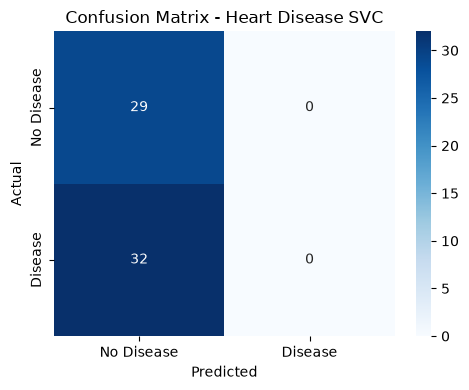

In [14]:
print("Classification report")
print("---------------------")
print(classification_report(
    testing_results["heart_disease"],
    testing_results["Predictions"],
    target_names=["No Heart Disease (0)", "Heart Disease (1)"],
    zero_division=0
))

conf_matrix = confusion_matrix(
    testing_results["heart_disease"],
    testing_results["Predictions"]
)

conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: No Disease", "Actual: Disease"],
    columns=["Predicted: No Disease", "Predicted: Disease"]
)

print("Confusion matrix")
print("----------------")
print(conf_matrix_df)

plt.figure(figsize=(5, 4))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Heart Disease SVC")
plt.tight_layout()
plt.show()

## 7. Try it the way the app does

The next few cells repeat what happens when someone clicks **Predict Heart Disease** in the web app: take four numbers, put them in a one-row table, and ask the model for an answer. Change the values below and re-run the cells to see how the prediction moves.

### 7.1 The four inputs

In [15]:
# these are the same defaults the app starts with
age_input = 55
trestbps_input = 140
chol_input = 250
thalach_input = 150

print(
    f"Age: {age_input}, "
    f"Resting BP: {trestbps_input}, "
    f"Cholesterol: {chol_input}, "
    f"Max heart rate: {thalach_input}"
)

Age: 55, Resting BP: 140, Cholesterol: 250, Max heart rate: 150


### 7.2 Build the input row

The app builds a one-row DataFrame with the same column names, in the same order, that the model was trained on. If the order were different, the model would quietly read the wrong number as the wrong feature.

In [16]:
user_input = pd.DataFrame({
    "age": [age_input],
    "trestbps": [trestbps_input],
    "chol": [chol_input],
    "thalach": [thalach_input]
})[FEATURE_COLUMNS]

print("Input row:")
print(user_input)

Input row:
   age  trestbps  chol  thalach
0   55       140   250      150


### 7.3 Load the model and predict

In [17]:
with open("heart_disease_model.pkl", "rb") as model_file:
    model = pickle.load(model_file)

predicted_result = int(model.predict(user_input)[0])

if predicted_result == 1:
    prediction = "HEART DISEASE PRESENT"
else:
    prediction = "NO HEART DISEASE"

print("Prediction:", prediction)

Prediction: NO HEART DISEASE


## 8. Notes on the model and the app

A few things worth knowing about what this model can and can't do:

In [18]:
notes = pd.DataFrame({
    "Area": [
        "Inputs",
        "Model",
        "Evaluation",
        "App"
    ],
    "Note": [
        "Only four numbers are used. Real heart disease risk depends on much more, such as chest pain type, ECG results and family history.",
        "A plain SVC with default settings. The inputs are not scaled, so features with big numbers like cholesterol can outweigh smaller ones like age.",
        "Checked with accuracy, precision, recall, F1 and a confusion matrix on a held-out 20% of the rows.",
        "Streamlit gives the model a simple form: four number boxes and a predict button."
    ]
})

print(notes.to_string(index=False))

      Area                                                                                                                                            Note
    Inputs              Only four numbers are used. Real heart disease risk depends on much more, such as chest pain type, ECG results and family history.
     Model A plain SVC with default settings. The inputs are not scaled, so features with big numbers like cholesterol can outweigh smaller ones like age.
Evaluation                                              Checked with accuracy, precision, recall, F1 and a confusion matrix on a held-out 20% of the rows.
       App                                                                Streamlit gives the model a simple form: four number boxes and a predict button.


## 9. Running the app

Once the notebook has been run top to bottom, these files exist in the folder:

```text
Heart_Disease_ML/
├── Heart_Disease_ML.ipynb
├── heart_disease.csv
├── training-data.csv
├── testing-data.csv
├── model-predictions.csv
├── heart_disease_model.pkl      <- the model the app loads
├── app.py
└── requirements.txt
```

Start the app locally with:

```bash
streamlit run app.py
```

To put it online with Streamlit Community Cloud, push these three files to a GitHub repository and deploy `app.py` from there:

- `app.py`
- `requirements.txt`
- `heart_disease_model.pkl`

## 10. Wrapping up

The app takes age, resting blood pressure, cholesterol and maximum heart rate, sends them to an SVC trained on the UCI Cleveland data, and returns a yes/no prediction. The notebook is where that model is built, tested and saved, and the app just loads it and uses it.

Possible next steps: add feature scaling, try a few more of the dataset's columns, or compare the SVC with other models such as logistic regression or a random forest.

> This project is for learning only. It is not a medical device and shouldn't be used to diagnose or treat anyone.